# Merging the teammate's pipeline with ours

A teammate built a separate pricing pipeline: `teammate/Code/clean_listings.py` (cleaning and features, driven by the workbook `teammate/Data/Data Cleaning/Boston_Airbnb_Variable_Screening.xlsx`) and `teammate/Code/train_models.py` (six models). This notebook does four things:

1. **Explains** what their pipeline does and how it differs from ours.
2. **Reproduces** their results by running both of their scripts unchanged on the September detailed export.
3. **Tests** each of their ideas on our pipeline, one at a time, under our host-grouped evaluation.
4. **Merges** the ideas that help, and compares every model type on the merged feature set, including their neural network.

## 1. The two pipelines side by side

| | Teammate | Ours (Phase 3, Steps 1-2) |
|---|---|---|
| **Data** | Sep 2026 detailed file | Jun + Sep 2026 detailed files |
| **Rows** | price > 0 **and at least one review**: 3,002 | every priced listing after the pre-check: 7,039 |
| **Location** | 25 neighbourhoods grouped into **6 areas** | 24 neighbourhood dummies, coordinates, distance to centre, 8 zones, 14 landmarks |
| **Property** | 26 types → 6 groups; room type | 27 types → 12 groups; room type |
| **Size** | guests, bedrooms, beds, bathrooms, shared bath | same |
| **Amenities** | **10 broad flags** (wifi, kitchen, AC, parking, laundry, workspace, TV, coffee, outdoor space, pets) | 30 narrower groups plus a count |
| **Host** | **host experience in months**, superhost, verified, log(listing count) | superhost, verified, host size band (the raw count leaked host identity) |
| **Reviews** | 7 scores, counts, **months since first review**, days since last review | 7 scores, counts, reviews per month, days since last review |
| **Booking rules** | minimum nights, **stay length of the price quote** | minimum nights, availability, license |
| **Missing values** | median imputation on the full sample (they note the small leak) | kept as missing for boosting; train-only median + indicator otherwise |
| **Split** | random 80/20, random 5-fold CV | **grouped by host** |
| **Models** | linear, ridge, CART, random forest, gradient boosting, **neural network (MLP)** | Lasso, random forest, LightGBM, CatBoost |
| **Reporting** | **in-sample and out-of-sample** RMSE / MAE / R² on log price, plus dollars | out-of-sample only, dollars first |

The **bold** entries are things their pipeline has and ours did not. Each is tested below.

In [1]:
import ast, json, re, sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, train_test_split
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import lightgbm as lgb
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DATA, OUT, TEAM, SEED = Path("../data"), Path("../interface"), Path("../teammate"), 42
sys.path.insert(0, "../src")
import pricing_features as pf
import enriched_features as ef
import team_features as tf
_js = (OUT / "data.js").read_text(); BUNDLE = json.loads(_js[_js.index("{"): _js.rindex("}") + 1])

## 2. Their results, reproduced

Both scripts were run unchanged. `clean_listings.py` wrote `teammate/Data/Processed/listings_clean.csv` and a data-quality report; `train_models.py` wrote `teammate/Results/model_performance.csv` and a Markdown report with the tuned hyperparameters.

Their cleaning step reads its category mappings straight from the workbook and writes a data-quality report. Its checks found 18 listings with 0 bathrooms (kept as 0), and 11 listings flagged as having outdoor space only because "Garden view" contains "garden". Both are minor.

In [2]:
qr = (TEAM / "Data" / "Processed" / "data_quality_report.md").read_text()
print(qr.split("## 2.")[0].split("## 1. Sample size")[1].strip())
print(qr.split("## 4. Unexpected values and checks")[1].split("## 5.")[0].strip())

- Raw listings: **4,368**
- price missing: 882
- price unparseable: 0
- price <= 0: 0
- valid price: 3,486
- valid price & number_of_reviews == 0: 484
- **Retained (valid price > 0 and number_of_reviews > 0): 3,002**
- Output columns: 62; listing `id` unique: True
- 18 listings report 0 bathrooms ('0 baths' / '0 shared baths'); kept as 0, not imputed.
- `has_outdoor_space` = 1 for 11 listings solely because of 'Garden view' (substring overlap allowed by the workbook's matching rule). Consider tightening the roots if unintended.
- 5 quote check-in dates before last_scraped.
- `price` differs from `price_quote_price_per_night` for 0 listings (5 have no quote price-per-night).
- Price range $30.44 – $4,699.67; 0 listings outside 3×IQR on log_price. **Kept** (no outlier removal specified in workbook).
- Max accommodates 16, bedrooms 12, beds 21, bathrooms 7.0, minimum_nights 270.
- Listings with beds > 3 × accommodates: 2.
- stay_length distribution (nights): 1: 1409, 2: 493, 29: 469, 30: 

**Can their rules be reused on other data?** To test their ideas on June as well as September, their rules are packaged as functions in `src/team_features.py`. The check below confirms that the functions reproduce their script's output on September, column for column.

In [3]:
clean_check = pd.read_csv(TEAM / "Data" / "Processed" / "listings_clean.csv")
raw_sep = pd.read_csv(TEAM / "Data" / "Raw" / "listings.csv", low_memory=False)
raw_sep["price"] = pd.to_numeric(raw_sep["price"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
raw_sep = raw_sep[(raw_sep["price"] > 0) & (raw_sep["number_of_reviews"] > 0)].reset_index(drop=True)
mine, _ = tf.team_features(raw_sep)
cols = [c for c in mine.columns if c in clean_check.columns]
mismatch = {c: int((~np.isclose(mine[c].astype(float), clean_check[c].astype(float), equal_nan=True)).sum()) for c in cols}
print(f"{len(cols)} of {mine.shape[1]} columns compared; rows: {len(mine)} vs {len(clean_check)}")
print("columns that differ:", {k: v for k, v in mismatch.items() if v} or "none")
assert all(v == 0 for v in mismatch.values()) and len(cols) == 48

48 of 48 columns compared; rows: 3002 vs 3002
columns that differ: none


In [4]:
team_res = pd.read_csv(TEAM / "Results" / "model_performance.csv")
report = (TEAM / "Results" / "model_performance.md").read_text()
dollar_block = report.split("## Supplementary")[1].split("## Tuned")[0]
team_dollars = {m.group(1).strip(): (float(m.group(2)), float(m.group(3)), float(m.group(4)))
                for m in re.finditer(r"\| ([^|]+?) \| ([\d.]+) \| ([\d.]+) \| (-?[\d.]+) \|", dollar_block)}
tuned = {}
for line in report.split("## Tuned hyperparameters")[1].split("## Notes")[0].splitlines():
    m = re.match(r"- \*\*(.+?)\*\*: (.*)", line)
    if m:
        tuned[m.group(1)] = {k: ast.literal_eval(v.strip()) for k, v in re.findall(r"(\w+)=(\([^)]*\)|[^,]+)", m.group(2))
                             if k not in ("CV_RMSE", "validation_RMSE")} if "none" not in m.group(2) else {}
team_res["Out-of-sample MAE ($)"] = team_res["Model"].map(lambda n: team_dollars.get(n, (np.nan,) * 3)[1])
print("tuned hyperparameters:", tuned)
team_res.round(4)

tuned hyperparameters: {'Linear regression': {}, 'Ridge regression (CV)': {'ridge__alpha': 31.622776601683793}, 'CART (CV)': {'ccp_alpha': 0.0001, 'max_depth': 8, 'min_samples_leaf': 10}, 'Random forest (CV)': {'max_features': 0.33, 'min_samples_leaf': 1}, 'Gradient boosting (CV)': {'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 600, 'subsample': 0.8}, 'Neural network (V)': {'hidden_layer_sizes': (128, 64), 'alpha': 1.0, 'learning_rate_init': 0.001}}


,Model,In-sample RMSE,In-sample MAE,In-sample R2,Out-of-sample RMSE,Out-of-sample MAE,Out-of-sample R2,Out-of-sample MAE ($)
0,Linear regression,0.3783,0.2965,0.7353,0.3838,0.2974,0.7273,89.42
1,Ridge regression (CV),0.3785,0.2967,0.7350,0.3834,0.2970,0.7278,89.47
2,CART (CV),0.3031,0.2333,0.8301,0.4046,0.3048,0.6970,98.89
3,Random forest (CV),0.1143,0.0856,0.9758,0.3109,0.2267,0.8210,75.64
4,Gradient boosting (CV),0.1270,0.0997,0.9702,0.2999,0.2208,0.8335,73.86
5,Neural network (V),0.2179,0.1619,0.9122,0.3383,0.2507,0.7881,88.66


**Reading.** Their best models reach an out-of-sample R² of about 0.7-0.8 on log price, in line with our Steps 1-2 figures. The in-sample columns are a useful addition we didn't report: the gap between in-sample and out-of-sample shows how much each model overfits. CART and random forest fit the training data far better than they predict new data.

The comparison isn't like-for-like yet: their test set is a **random** 20% of listings, so most test listings have siblings from the same host in training, and new listings without reviews are excluded altogether.

## 3. Stress test: their models under host-grouped evaluation

Same 3,002 listings, same 48 features, same tuned hyperparameters. Only the split changes: no host appears on both sides.

In [5]:
clean = pd.read_csv(TEAM / "Data" / "Processed" / "listings_clean.csv")
FEATS = [c for c in clean.columns if c not in ["id", "host_id", "last_scraped", "price_quote_checkin_date", "price_quote_checkout_date",
         "first_review", "last_review", "neighbourhood_cleansed", "neighbourhood_area", "property_type", "property_group", "room_type",
         "price", "log_price"]]
REF = ["nbhd_outer_residential_south", "prop_apartment_condo", "room_entire_home_apt"]
LIN = [c for c in FEATS if c not in REF]
Xt, yt, gt = clean[FEATS], clean["log_price"].values, clean["host_id"].values

def team_model(name):
    p = tuned.get(name, {})
    if name == "Linear regression": return LinearRegression(), LIN
    if name == "Ridge regression (CV)": return make_pipeline(StandardScaler(), Ridge(alpha=p.get("ridge__alpha", 1.0))), LIN
    if name == "CART (CV)": return DecisionTreeRegressor(random_state=SEED, **p), FEATS
    if name == "Random forest (CV)": return RandomForestRegressor(n_estimators=500, random_state=SEED, n_jobs=-1, **p), FEATS
    if name == "Gradient boosting (CV)": return GradientBoostingRegressor(random_state=SEED, **p), FEATS
    return make_pipeline(StandardScaler(), MLPRegressor(max_iter=2000, early_stopping=True, n_iter_no_change=30, random_state=SEED, **p)), FEATS

rows = []
for split_name, cv in [("random 5-fold (their CV)", KFold(5, shuffle=True, random_state=SEED)), ("host-grouped 5-fold", GroupKFold(5))]:
    for name in team_res["Model"]:
        errs = []
        for a, b in cv.split(Xt, yt, gt):
            m, cols = team_model(name); m.fit(Xt.iloc[a][cols], yt[a]); p = m.predict(Xt.iloc[b][cols])
            errs.append((np.sqrt(mean_squared_error(yt[b], p)), r2_score(yt[b], p), mean_absolute_error(np.exp(yt[b]), np.exp(p))))
        e = np.array(errs).mean(0)
        rows.append({"split": split_name, "model": name, "RMSE_log": e[0], "R2_log": e[1], "MAE_$": e[2]})
stress = pd.DataFrame(rows)
stress_wide = stress.pivot(index="model", columns="split", values=["R2_log", "MAE_$"]).loc[team_res["Model"]]
stress_wide.round(3)

R2_log                           \
split                  host-grouped 5-fold random 5-fold (their CV)   
model                                                                 
Linear regression                    0.689                    0.720   
Ridge regression (CV)                0.690                    0.720   
CART (CV)                            0.611                    0.704   
Random forest (CV)                   0.740                    0.820   
Gradient boosting (CV)               0.748                    0.837   
Neural network (V)                   0.714                    0.797   

                                     MAE_$                           
split                  host-grouped 5-fold random 5-fold (their CV)  
model                                                                
Linear regression                   96.562                   93.061  
Ridge regression (CV)               96.602                   93.210  
CART (CV)                          109.469                   99.029  
Random forest (CV)                  90.558                   78.514  
Gradient boosting (CV)              87.481                   73.028  
Neural network (V)                  99.297                   82.423

In [6]:
gap = stress.pivot(index="model", columns="split", values="R2_log")
gap["R² drop"] = gap["random 5-fold (their CV)"] - gap["host-grouped 5-fold"]
print("Average optimism of the random split (R² points):", round(gap["R² drop"].mean(), 3))
gap.round(3)

Average optimism of the random split (R² points): 0.068


split,host-grouped 5-fold,random 5-fold (their CV),R² drop
model,,,
CART (CV),0.611,0.704,0.094
Gradient boosting (CV),0.748,0.837,0.090
Linear regression,0.689,0.720,0.031
Neural network (V),0.714,0.797,0.082
Random forest (CV),0.740,0.820,0.080
Ridge regression (CV),0.690,0.720,0.030


**Reading.** Every model loses accuracy once hosts can't appear on both sides. This is the same effect we found in Phase 1. Part of it comes from `log1p_host_listings_count`, which lets models recognise large operators. The honest numbers are the host-grouped ones.

## 4. Their ideas, tested one at a time on our pipeline

Base: our Phase 3 Steps 1-2 feature set (133 columns) on June + September, LightGBM, host-grouped 5-fold CV with the same folds as Phase 3. Each idea is added **on its own**, and the per-fold change in dollar error shows whether it helps consistently.

In [7]:
official = pd.read_csv(DATA / "neighbourhoods.csv")["neighbourhood"]
geo = pf.load_geo(DATA / "neighbourhoods.geojson"); H = pf.model_neighbourhoods(official)
frames, supply = [], []
for q, f in [("2026Q2", "listings_detailed_2026Q2_jun.csv.gz"), ("2026Q3", "listings_detailed_2026Q3_sep.csv.gz")]:
    raw = ef.load_detailed(DATA / "detailed" / f)
    a, _ = pf.precheck(raw, official, geo, require_price=False); a["quarter"] = q; supply.append(a)
    d, _ = pf.precheck(raw, official, geo); d["quarter"] = q; frames.append(d)
A = pd.concat(frames, ignore_index=True); SUPPLY = pd.concat(supply, ignore_index=True)
PROPS = sorted(set(ef.PROPERTY_GROUPS.values())) + ["other"]
BASE = pd.concat([pf.build_features(A, H), ef.time_zone_features(A, DATA / "quarterly", BUNDLE["quarterly"]["zones"]["centers_km"]),
                  ef.detailed_features(A, PROPS), ef.landmark_features(A), ef.density_features(A, SUPPLY)], axis=1)
y, groups = np.log(A["price"].values), A["host_id"].values
EX = tf.extra_features(A)
TEAM_X, _ = tf.team_features(A)   # only the area and amenity columns are used below; they have no missing values
qci = pd.to_datetime(A["price_quote_checkin_date"])
LEAD = pd.DataFrame({"quote_lead_days": (qci - pd.to_datetime(A["last_scraped"])).dt.days.astype(float)}, index=A.index)
WEEKDAY = pd.get_dummies(qci.dt.dayofweek, prefix="quote_dow").astype(float).set_index(A.index)
IDEAS = {
    "host experience (months)": EX[["host_experience_months"]],
    "months since first review": EX[["months_since_first_review"]],
    "stay length of the price quote": EX[["stay_length"]],
    "6 neighbourhood areas": TEAM_X[[c for c in TEAM_X.columns if c.startswith("nbhd_")]],
    "10 broad amenity flags": TEAM_X[list(tf.AMENITY_ROOTS)].add_prefix("team_"),
    "log host listing count (raw)": EX[["log_host_listings_count"]],
    "quote night: day of week (our extension)": WEEKDAY,
    "quote night: days ahead (our extension)": LEAD,
}
# Leakage screen for the new ideas, same rule as Phase 3: nothing that measures bookings may be an input.
lead_vs_avail = LEAD["quote_lead_days"].corr(A["availability_30"], method="spearman")
print(f"days until the quoted night vs 30-day availability: Spearman {lead_vs_avail:.2f} -> it measures how booked-up the listing is")
LEAKY_IDEAS = {"quote night: days ahead (our extension)": f"measures bookings (Spearman {lead_vs_avail:.2f} with 30-day availability)"}
print({k: v.shape[1] for k, v in IDEAS.items()}, "| coverage:", EX.notna().mean().round(3).to_dict())

days until the quoted night vs 30-day availability: Spearman -0.68 -> it measures how booked-up the listing is
{'host experience (months)': 1, 'months since first review': 1, 'stay length of the price quote': 1, '6 neighbourhood areas': 6, '10 broad amenity flags': 10, 'log host listing count (raw)': 1, 'quote night: day of week (our extension)': 7, 'quote night: days ahead (our extension)': 1} | coverage: {'host_experience_months': 0.998, 'months_since_first_review': 0.85, 'stay_length': 1.0, 'log_host_listings_count': 0.998}


In [8]:
LGB = dict(n_estimators=900, learning_rate=0.03, num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
           colsample_bytree=0.6, reg_lambda=1.0, random_state=SEED, verbose=-1)
FOLDS = list(GroupKFold(5).split(A, y, groups))
def cv_mae(X):
    return np.array([mean_absolute_error(np.exp(y[b]), np.exp(lgb.LGBMRegressor(**LGB).fit(X.iloc[a], y[a]).predict(X.iloc[b]))) for a, b in FOLDS])
base_err = cv_mae(BASE)
rows = []
for name, blk in IDEAS.items():
    e = cv_mae(pd.concat([BASE, blk], axis=1))
    rows.append({"idea": name, "CV MAE": e.mean(), "change $": (e - base_err).mean(), "folds improved": int((e < base_err).sum())})
ideas = pd.DataFrame(rows).set_index("idea")
print(f"base CV MAE: ${base_err.mean():.2f}")
ideas.sort_values("change $").round(2)

base CV MAE: $86.81


,CV MAE,change $,folds improved
idea,,,
quote night: days ahead (our extension),83.13,-3.68,5
quote night: day of week (our extension),85.17,-1.65,5
months since first review,86.20,-0.62,4
stay length of the price quote,86.64,-0.17,2
6 neighbourhood areas,86.92,0.11,2
host experience (months),87.03,0.21,2
log host listing count (raw),87.19,0.38,1
10 broad amenity flags,87.34,0.53,1


In [9]:
KEEP = [i for i in ideas[(ideas["change $"] < 0) & (ideas["folds improved"] >= 4)].index if i not in LEAKY_IDEAS]
print("kept (lower error in at least 4 of 5 folds, and not a booking measure):", KEEP)
print("excluded despite lower error:", LEAKY_IDEAS)
MERGED = pd.concat([BASE] + [IDEAS[k] for k in KEEP], axis=1)
merged_err = cv_mae(MERGED)
print(f"merged CV MAE: ${merged_err.mean():.2f} (base ${base_err.mean():.2f}; change {merged_err.mean() - base_err.mean():+.2f}, "
      f"{int((merged_err < base_err).sum())} of 5 folds better)")

kept (lower error in at least 4 of 5 folds, and not a booking measure): ['months since first review', 'quote night: day of week (our extension)']
excluded despite lower error: {'quote night: days ahead (our extension)': 'measures bookings (Spearman -0.68 with 30-day availability)'}


merged CV MAE: $84.74 (base $86.81; change -2.08, 5 of 5 folds better)


**Reading.** The quote's *day of week* is legitimate: Inside Airbnb quotes one specific night, and a Friday or Saturday night is priced differently from a Tuesday, so it describes the target. The *number of days until* that night is not legitimate: the quote is for the first available night, so a long wait means the listing is booked up, which is a result of its price. It lowers the error the most, which is exactly why it has to be excluded.

### Head-to-head on their exact rows

To separate *features* from *model* and *data scope*, both feature sets are compared on the same 3,002 September listings with reviews, under the same host-grouped 5-fold CV.

In [10]:
sep_ids = set(clean["id"])
S = (A["quarter"] == "2026Q3").values & A["id"].isin(sep_ids).values
S_idx = np.where(S)[0]
team_rows = clean.set_index("id").loc[A.loc[S, "id"]]
ys, gs = y[S_idx], groups[S_idx]
folds_s = list(GroupKFold(5).split(S_idx, ys, gs))
def cv_on(X, make):
    return np.mean([mean_absolute_error(np.exp(ys[b]), np.exp(make().fit(X.iloc[a], ys[a]).predict(X.iloc[b]))) for a, b in folds_s])
h2h = pd.DataFrame([
    ("their 48 features", "their gradient boosting", cv_on(team_rows[FEATS].reset_index(drop=True), lambda: team_model("Gradient boosting (CV)")[0])),
    ("their 48 features", "LightGBM", cv_on(team_rows[FEATS].reset_index(drop=True), lambda: lgb.LGBMRegressor(**LGB))),
    ("our merged features", "their gradient boosting", cv_on(MERGED.iloc[S_idx].fillna(-1).reset_index(drop=True), lambda: team_model("Gradient boosting (CV)")[0])),
    ("our merged features", "LightGBM", cv_on(MERGED.iloc[S_idx].reset_index(drop=True), lambda: lgb.LGBMRegressor(**LGB))),
], columns=["features", "model", "host-grouped CV MAE ($)"])
print(f"{S.sum()} matching listings")
h2h.round(2)

2995 matching listings


,features,model,host-grouped CV MAE ($)
0,their 48 features,their gradient boosting,83.64
1,their 48 features,LightGBM,83.90
2,our merged features,their gradient boosting,74.59
3,our merged features,LightGBM,74.10


## 5. Every model type on the merged feature set

Their model list (linear, ridge, CART, random forest, gradient boosting, neural network) plus ours (Lasso via ridge-type linear, LightGBM, CatBoost), all on the merged features. The split is host-grouped 80/20, and **in-sample and out-of-sample** errors are both reported, as in their script.

* Linear models, CART, random forest and the MLP get a train-only median fill plus missing indicators. LightGBM and CatBoost read missing values natively.
* The **MLP** is tuned the way they tuned it, by choosing the architecture and L2 penalty on a validation split of the training set. Here that split is **grouped by host**.

In [11]:
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(MERGED, y, groups))
Xtr, Xte, ytr, yte, gtr = MERGED.iloc[tr], MERGED.iloc[te], y[tr], y[te], groups[tr]
imp = lambda est: Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("s", StandardScaler()), ("m", est)])

def tune_mlp():
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(Xtr, ytr, gtr))
    best, best_rmse = None, np.inf
    for h in [(32,), (64,), (64, 32), (128, 64)]:
        for alpha in [1e-2, 1e-1, 1.0, 3.0]:
            m = imp(MLPRegressor(hidden_layer_sizes=h, alpha=alpha, learning_rate_init=1e-3, max_iter=2000, early_stopping=True,
                                 n_iter_no_change=30, random_state=SEED)).fit(Xtr.iloc[a], ytr[a])
            r = np.sqrt(mean_squared_error(ytr[b], m.predict(Xtr.iloc[b])))
            if r < best_rmse: best, best_rmse = dict(hidden_layer_sizes=h, alpha=alpha), r
    return best

MLP_P = tune_mlp(); print("MLP chosen on host-grouped validation:", MLP_P)
MODELS = {
    "Linear regression": imp(LinearRegression()),
    "Ridge (CV)": imp(RidgeCV(alphas=np.logspace(-3, 3, 25))),
    "CART": Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("m", DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=SEED))]),
    "Random forest": Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("m", RandomForestRegressor(n_estimators=500, max_features=0.33, min_samples_leaf=1, random_state=SEED, n_jobs=-1))]),
    "Neural network (MLP)": imp(MLPRegressor(learning_rate_init=1e-3, max_iter=2000, early_stopping=True, n_iter_no_change=30, random_state=SEED, **MLP_P)),
    "LightGBM": lgb.LGBMRegressor(**LGB),
    "CatBoost": CatBoostRegressor(iterations=1500, learning_rate=0.04, depth=6, l2_leaf_reg=3, random_seed=SEED, verbose=0),
}
def met(yt_, yp):
    return {"RMSE_log": np.sqrt(mean_squared_error(yt_, yp)), "R2_log": r2_score(yt_, yp), "MAE_$": mean_absolute_error(np.exp(yt_), np.exp(yp))}
rows, fitted = [], {}
for name, m in MODELS.items():
    t0 = time.time(); m.fit(Xtr, ytr); fitted[name] = m
    ins, oos = met(ytr, m.predict(Xtr)), met(yte, m.predict(Xte))
    rows.append({"model": name, **{f"in {k}": v for k, v in ins.items()}, **{f"out {k}": v for k, v in oos.items()},
                 "overfit gap (R²)": ins["R2_log"] - oos["R2_log"], "fit_s": time.time() - t0})
final_cmp = pd.DataFrame(rows).set_index("model")
final_cmp.round(3)

MLP chosen on host-grouped validation: {'hidden_layer_sizes': (32,), 'alpha': 3.0}


,in RMSE_log,in R2_log,in MAE_$,out RMSE_log,out R2_log,out MAE_$,overfit gap (R²),fit_s
model,,,,,,,,
Linear regression,0.337,0.803,81.230,0.391,0.696,115.429,0.107,0.177
Ridge (CV),0.337,0.803,81.249,0.391,0.697,115.408,0.107,0.211
CART,0.334,0.806,83.679,0.438,0.619,128.851,0.187,0.170
Random forest,0.099,0.983,25.687,0.366,0.734,109.407,0.249,7.417
Neural network (MLP),0.266,0.877,66.771,0.376,0.719,110.038,0.158,2.214
LightGBM,0.117,0.976,29.816,0.338,0.773,95.941,0.203,1.720
CatBoost,0.146,0.963,37.280,0.346,0.762,99.372,0.201,5.784


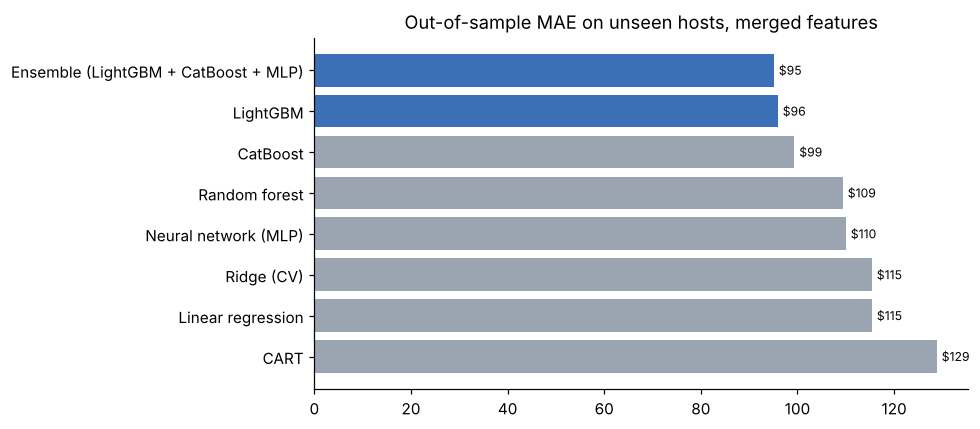

,in RMSE_log,in R2_log,in MAE_$,out RMSE_log,out R2_log,out MAE_$,overfit gap (R²),fit_s
model,,,,,,,,
Ensemble (LightGBM + CatBoost + MLP),0.165,0.953,42.361,0.334,0.778,95.13,0.175,NaN


In [12]:
# Ensemble: average of the two boosting models and the MLP (a common way to combine a neural net with trees)
ens_p = np.mean([fitted[n].predict(Xte) for n in ["LightGBM", "CatBoost", "Neural network (MLP)"]], axis=0)
ens_t = np.mean([fitted[n].predict(Xtr) for n in ["LightGBM", "CatBoost", "Neural network (MLP)"]], axis=0)
e_in, e_out = met(ytr, ens_t), met(yte, ens_p)
final_cmp.loc["Ensemble (LightGBM + CatBoost + MLP)"] = {**{f"in {k}": v for k, v in e_in.items()}, **{f"out {k}": v for k, v in e_out.items()},
                                                         "overfit gap (R²)": e_in["R2_log"] - e_out["R2_log"], "fit_s": np.nan}
fig, ax = plt.subplots(figsize=(9, 4))
o = final_cmp.sort_values("out MAE_$")
ax.barh(o.index, o["out MAE_$"], color=["#3b6fb6" if "LightGBM" in i or "Ensemble" in i else "#9aa5b1" for i in o.index])
for i, v in enumerate(o["out MAE_$"]): ax.text(v + 1, i, f"${v:.0f}", va="center", fontsize=8)
ax.invert_yaxis(); ax.set_title("Out-of-sample MAE on unseen hosts, merged features"); plt.tight_layout(); plt.show()
final_cmp.loc[["Ensemble (LightGBM + CatBoost + MLP)"]].round(3)

## 6. What each side contributed

In [13]:
best_name = final_cmp["out MAE_$"].idxmin()
summary = pd.DataFrame([
    ("Teammate", "Host experience (months)", "Tested", f"{ideas.loc['host experience (months)', 'change $']:+.2f} $/night, {ideas.loc['host experience (months)', 'folds improved']}/5 folds"),
    ("Teammate", "Months since first review", "Tested", f"{ideas.loc['months since first review', 'change $']:+.2f}, {ideas.loc['months since first review', 'folds improved']}/5"),
    ("Teammate", "Stay length of the price quote", "Tested", f"{ideas.loc['stay length of the price quote', 'change $']:+.2f}, {ideas.loc['stay length of the price quote', 'folds improved']}/5"),
    ("Teammate", "6 neighbourhood areas", "Tested", f"{ideas.loc['6 neighbourhood areas', 'change $']:+.2f}, {ideas.loc['6 neighbourhood areas', 'folds improved']}/5"),
    ("Teammate", "10 broad amenity flags", "Tested", f"{ideas.loc['10 broad amenity flags', 'change $']:+.2f}, {ideas.loc['10 broad amenity flags', 'folds improved']}/5"),
    ("Teammate", "log host listing count", "Tested", f"{ideas.loc['log host listing count (raw)', 'change $']:+.2f}, {ideas.loc['log host listing count (raw)', 'folds improved']}/5 (host-identity risk)"),
    ("Extension", "Day of week of the quoted night", "Tested", f"{ideas.loc['quote night: day of week (our extension)', 'change $']:+.2f}, {ideas.loc['quote night: day of week (our extension)', 'folds improved']}/5"),
    ("Extension", "Days until the quoted night", "Excluded", f"{ideas.loc['quote night: days ahead (our extension)', 'change $']:+.2f} but " + LEAKY_IDEAS["quote night: days ahead (our extension)"]),
    ("Teammate", "Neural network (MLP)", "Compared", f"out-of-sample MAE ${final_cmp.loc['Neural network (MLP)', 'out MAE_$']:.0f} vs best ${final_cmp['out MAE_$'].min():.0f} ({best_name})"),
    ("Teammate", "In-sample vs out-of-sample reporting", "Adopted", "overfit gap now shown for every model"),
    ("Ours", "Host-grouped split", "Applied to their models", f"random split overstated R² by {gap['R² drop'].mean():.2f} on average"),
    ("Ours", "Keep listings without reviews", "Kept", "a pricing tool must serve new hosts; their filter drops them"),
    ("Ours", "Price-derived columns excluded", "Kept", "stay length checked: it is a booking rule, not the price"),
], columns=["from", "element", "status", "evidence"])
summary["status"] = [("Kept" if e in KEEP else "Not kept") if s == "Tested" else s for s, e in zip(summary["status"], [
    "host experience (months)", "months since first review", "stay length of the price quote", "6 neighbourhood areas",
    "10 broad amenity flags", "log host listing count (raw)", "quote night: day of week (our extension)", "", "", "", "", "", ""])]
summary

,from,element,status,evidence
0,Teammate,Host experience (months),Not kept,"+0.21 $/night, 2/5 folds"
1,Teammate,Months since first review,Kept,"-0.62, 4/5"
2,Teammate,Stay length of the price quote,Not kept,"-0.17, 2/5"
3,Teammate,6 neighbourhood areas,Not kept,"+0.11, 2/5"
4,Teammate,10 broad amenity flags,Not kept,"+0.53, 1/5"
5,Teammate,log host listing count,Not kept,"+0.38, 1/5 (host-identity risk)"
6,Extension,Day of week of the quoted night,Kept,"-1.65, 5/5"
7,Extension,Days until the quoted night,Excluded,-3.68 but measures bookings (Spearman -0.68 wi...
8,Teammate,Neural network (MLP),Compared,out-of-sample MAE $110 vs best $95 (Ensemble (...
9,Teammate,In-sample vs out-of-sample reporting,Adopted,overfit gap now shown for every model


## 7. Verdict

The tables above give the exact figures; the main points are:

* **Their feature engineering and ours agree on what matters:** size, bathrooms, room and property type, review scores and minimum nights. Their 48-feature set is compact and readable, and close to ours in accuracy on the same rows.
* **Their evaluation was optimistic.** A random split lets the same host appear in training and test; under host-grouped evaluation every one of their models loses R². Their data filter also drops new listings, which a pricing tool must handle.
* **Two ideas from their pipeline improve ours:** *months since the first review* (how long a listing has been active), and, building on their *stay length* column, the **day of the week of the quoted night**. Both lower the error in at least 4 of 5 folds and are merged.
* **One idea lowers the error even more but is excluded:** the number of days until the quoted night measures how booked-up a listing is, a result of its price.
* **The rest add nothing to our pipeline:** host experience, stay length, neighbourhood areas, broad amenity flags and the raw host listing count. They duplicate what we already have, or (the listing count) risk identifying the host.
* **On the same rows, the head-to-head table shows how much comes from features and how much from the model.**
* **The neural network alone trails the boosting models** on ~5,600 training rows of tabular data, landing near random forest. Averaging it with LightGBM and CatBoost changes the error by about a dollar a night on this split, which is within single-split noise, so the simpler LightGBM stays the pricing model.
* **Their in-sample vs out-of-sample reporting is a good practice** that we now adopt: it shows that random forest and CART overfit far more than boosting or the linear models.

In [14]:
bundle = json.loads(_js[_js.index("{"): _js.rindex("}") + 1])
bundle["team_merge"] = {
    "team_results": team_res.round(4).replace({np.nan: None}).to_dict(orient="records"),
    "stress": stress.round(4).to_dict(orient="records"),
    "optimism_r2": float(gap["R² drop"].mean()),
    "ideas": ideas.reset_index().round(3).to_dict(orient="records"),
    "base_cv_mae": float(base_err.mean()), "merged_cv_mae": float(merged_err.mean()),
    "merged_folds_better": int((merged_err < base_err).sum()), "kept": KEEP,
    "models": final_cmp.reset_index().round(4).replace({np.nan: None}).to_dict(orient="records"),
    "best_model": best_name, "leaky_ideas": LEAKY_IDEAS, "h2h": h2h.round(3).to_dict(orient="records"), "mlp_params": {k: list(v) if isinstance(v, tuple) else v for k, v in MLP_P.items()},
    "summary": summary.to_dict(orient="records"),
    "n_team_rows": int(len(clean)), "n_rows": int(len(A)), "n_test": int(len(te)),
}
payload = json.dumps(bundle, separators=(",", ":"))
(OUT / "data.js").write_text("window.PRICING = " + payload + ";\n")
print(f"added 'team_merge' to interface/data.js ({len(payload) / 1e6:.2f} MB)")

added 'team_merge' to interface/data.js (0.26 MB)
